In [1]:
import pandas as pd
import scipy
import sklearn
import numpy as np

Agent =
1. device forwarding/modifying the traffic
NAT device (e.g., home router translating private → public IP)

Web proxy server

Load balancer

Firewall or gateway

2. Monitoring agent:
SIEM agents (e.g., Splunk, Wazuh)

EDR/XDR security agents

Packet capture agents

SNMP agents

3. Application Agents:
Backup agents

VPN clients

Remote management agents

Docker/Kubernetes node agents

4. Cloud Services / SaaS Middleman

In [2]:
col_names = ["Flow", "Agent IP", "src Port", "dst Port", "src_MAC", "dst_MAC", "ethernet_type", "dst vlan", "src vlan", "src_ip", "dst_ip", "tcp6 udp17", "ip_type_of_service", "ip_time_to_live", "src port transport level", "dst port transport level", "tcp flags", "packet size", "ip size", "sampling rate"]
df_data_2 = pd.read_csv("./Data/Data_2.csv", names = col_names, dtype= str)
df_test_SFlow = pd.read_csv("./Data/test_SFLow_data.csv", names = col_names, dtype= str)

In [3]:
display(df_data_2.head())
display(df_test_SFlow.head())
print("df data shape", df_data_2.shape)
print("df test shape", df_test_SFlow.shape)

,Flow,Agent IP,src Port,dst Port,src_MAC,dst_MAC,ethernet_type,dst vlan,src vlan,src_ip,dst_ip,tcp6 udp17,ip_type_of_service,ip_time_to_live,src port transport level,dst port transport level,tcp flags,packet size,ip size,sampling rate
0,FLOW,203.30.38.251,193,130,0031466b23cf,00239cd087c1,0x0800,919,919,74.125.10.59,137.132.38.238,17,0x00,63,443,62758,0x00,1396,1378,2048
1,FLOW,203.30.38.251,193,130,0031466b23cf,00239cd087c1,0x0800,919,919,173.194.22.215,137.132.228.29,6,0x00,63,443,39740,0x10,1438,1420,2048
2,FLOW,203.30.38.251,199,131,544b8cf9a7df,001cb0c88e40,0x0800,600,43,193.62.193.9,202.130.56.153,6,0x00,246,80,35794,0x18,272,250,2048
3,FLOW,203.30.38.251,193,131,0031466b23cf,001cb0c88e40,0x0800,919,43,74.125.130.132,192.122.131.33,6,0x00,52,443,5287,0x10,1418,1400,2048
4,FLOW,203.30.38.251,129,193,00135f21bc80,0031466b23cf,0x0800,11,919,155.69.160.69,74.125.68.139,17,0x60,59,48361,443,0x00,89,67,2048


,Flow,Agent IP,src Port,dst Port,src_MAC,dst_MAC,ethernet_type,dst vlan,src vlan,src_ip,dst_ip,tcp6 udp17,ip_type_of_service,ip_time_to_live,src port transport level,dst port transport level,tcp flags,packet size,ip size,sampling rate
FLOW,aa.aa.aa.aa,258,20,204e71cf1b0f,002438aa0a00,0x0800,3012,3012,152.3.219.19,198.71.44.98,50,0x00,245,0,0,0x00,1518,1496,2048,NaN
FLOW,aa.aa.aa.aa,258,20,204e71cf1b0f,002438aa0a00,0x0800,3012,3012,152.3.219.19,198.71.44.98,50,0x00,245,0,0,0x00,1518,1496,2048,NaN
FLOW,aa.aa.aa.aa,258,20,204e71cf1b0f,002438aa0a00,0x0800,3012,3012,152.3.219.19,198.71.44.98,50,0x00,245,0,0,0x00,1518,1496,2048,NaN
FLOW,aa.aa.aa.aa,258,20,204e71cf1b0f,002438aa0a00,0x0800,3012,3012,152.3.219.19,198.71.44.98,50,0x00,245,0,0,0x00,1518,1496,2048,NaN
FLOW,aa.aa.aa.aa,258,20,204e71cf1b0f,002438aa0a00,0x0800,3012,3012,152.3.219.19,198.71.44.98,50,0x00,245,0,0,0x00,1518,1496,2048,NaN


df data shape (177232, 20)
df test shape (1200, 20)


### Mac Analysis

In [4]:
# looks like a lot of the source macs are in scientific notation in source data. 
# Discard these data for MAC address analysis
mac_df = df_data_2[~df_data_2["src_MAC"].str.contains(r"E", na=False) 
                   & ~(df_data_2["src_MAC"] == "1")
                   & ~df_data_2["dst_MAC"].str.contains(r"E", na=False)
                   & ~(df_data_2["dst_MAC"] == "1")]
display(mac_df)

,Flow,Agent IP,src Port,dst Port,src_MAC,dst_MAC,ethernet_type,dst vlan,src vlan,src_ip,dst_ip,tcp6 udp17,ip_type_of_service,ip_time_to_live,src port transport level,dst port transport level,tcp flags,packet size,ip size,sampling rate
0,FLOW,203.30.38.251,193,130,0031466b23cf,00239cd087c1,0x0800,919,919,74.125.10.59,137.132.38.238,17,0x00,63,443,62758,0x00,1396,1378,2048
1,FLOW,203.30.38.251,193,130,0031466b23cf,00239cd087c1,0x0800,919,919,173.194.22.215,137.132.228.29,6,0x00,63,443,39740,0x10,1438,1420,2048
2,FLOW,203.30.38.251,199,131,544b8cf9a7df,001cb0c88e40,0x0800,600,43,193.62.193.9,202.130.56.153,6,0x00,246,80,35794,0x18,272,250,2048
3,FLOW,203.30.38.251,193,131,0031466b23cf,001cb0c88e40,0x0800,919,43,74.125.130.132,192.122.131.33,6,0x00,52,443,5287,0x10,1418,1400,2048
4,FLOW,203.30.38.251,129,193,00135f21bc80,0031466b23cf,0x0800,11,919,155.69.160.69,74.125.68.139,17,0x60,59,48361,443,0x00,89,67,2048
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
177227,FLOW,203.30.38.251,193,131,0031466b23cf,001cb0c88e40,0x0800,919,43,74.125.10.23,192.122.131.146,6,0x00,63,443,50177,0x10,1490,1472,2048
177228,FLOW,203.30.38.251,200,199,80711fc76001,ccef48570144,0x0800,4095,601,13.107.4.50,210.48.222.13,6,0x00,112,80,50771,0x10,1448,1426,2048
177229,FLOW,203.30.38.251,200,131,80711fc76001,001cb0c88e40,0x0800,280,43,171.67.77.19,192.122.131.36,6,0x00,56,80,10452,0x10,1522,1500,2048
177230,FLOW,203.30.38.251,199,129,544b8cf9a7df,00135f21bc80,0x0800,600,11,133.11.245.204,155.69.59.240,17,0x00,55,50553,4500,0x10,150,128,2048


In [5]:
# Curious about srcs that arent dsts and vice versa

# Stack src and dst MACs into one long column for counting
all_macs = pd.concat([mac_df["src_MAC"], mac_df["dst_MAC"]])

# Count total transmissions involving each MAC (either as src or dst)
mac_counts = all_macs.value_counts().reset_index()
mac_counts.columns = ["MAC", "total_transmissions"]

# MACs that are destinations but not sources
dst_not_src_MAC = np.setdiff1d(mac_df["dst_MAC"].unique(), mac_df["src_MAC"].unique())
# MACs that are sources but not destinations
src_not_dst_MAC = np.setdiff1d(mac_df["src_MAC"].unique(), mac_df["dst_MAC"].unique())

# Filter counts for those MACs only, then sort descending
dst_only_counts = mac_counts[mac_counts["MAC"].isin(dst_not_src_MAC)].sort_values("total_transmissions", ascending=False)
src_only_counts = mac_counts[mac_counts["MAC"].isin(src_not_dst_MAC)].sort_values("total_transmissions", ascending=False)

print("=== Destination-only MACs (not seen as source) ===")
display(dst_only_counts)

print("\n=== Source-only MACs (not seen as destination) ===")
display(src_only_counts)

=== Destination-only MACs (not seen as source) ===


,MAC,total_transmissions
13,2c2172f7f437,5462
29,00055f1b7242,84
39,0881f4ed0fc0,29
43,88e0f3c33853,22
51,2c2172d57648,14
53,ffffffffffff,9
55,cc4e249c6300,8
61,0022be65f000,4
62,b0a86e7667f0,4
65,2c6bf5d277ca,3



=== Source-only MACs (not seen as destination) ===


,MAC,total_transmissions
16,5c5eabb2a7cd,1538
24,84b59cfbe2b2,190
28,00239cdbae77,88
34,00155dfbf011,49
36,cc4e249b8a00,40
49,00270dc96840,14
57,2c6bf5e84339,6
68,00a0de37fc83,2
69,64f69dd64b9e,2
84,5475d0a427c1,1


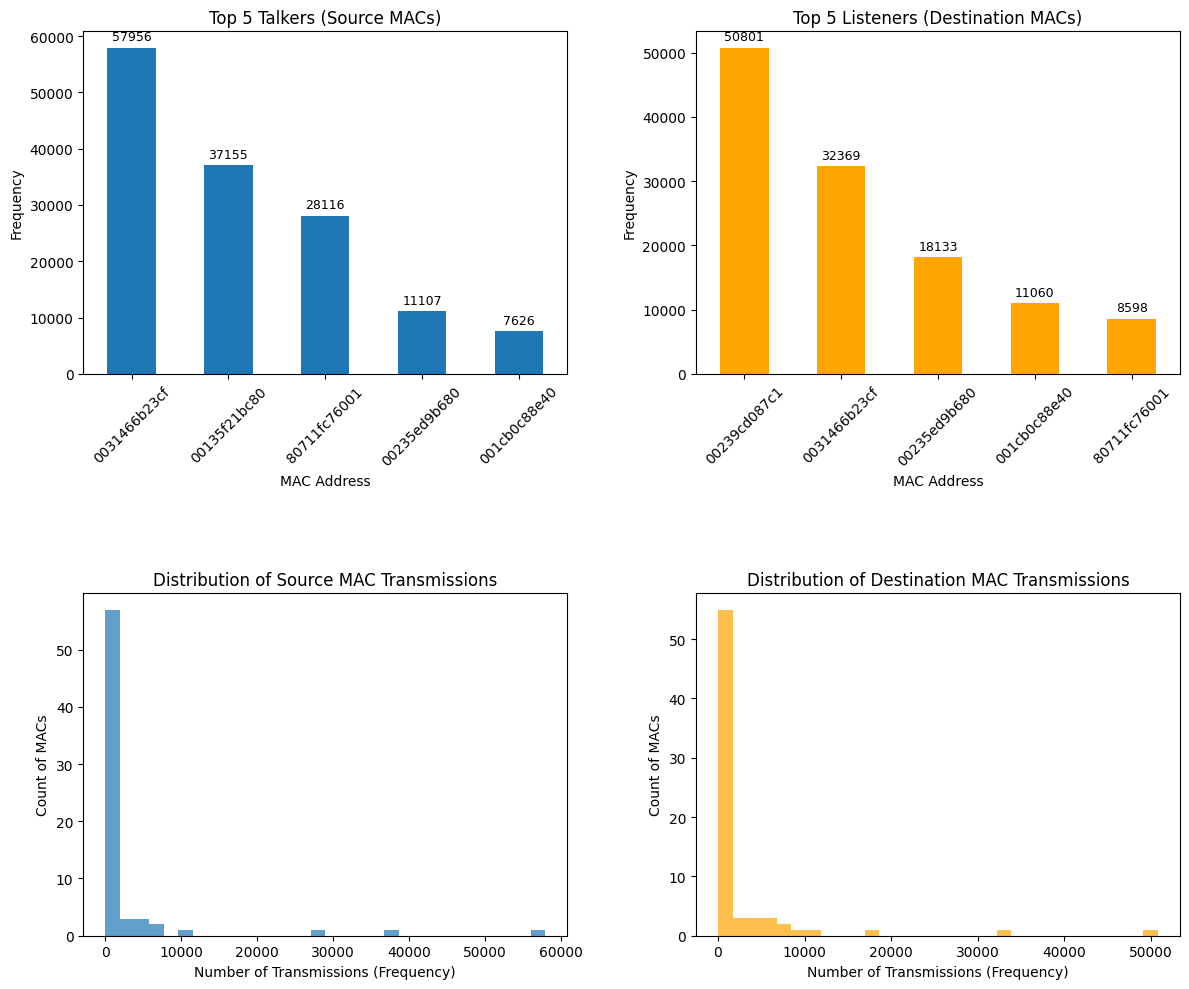

In [6]:
import matplotlib.pyplot as plt

# Prepare frequency DataFrames. 
# Turns out reset index causes ascending order, so no need sort_values("frequency", ascending=False) 
df_src_mac_freq = mac_df["src_MAC"].value_counts().reset_index().set_axis(["MAC", "frequency"], axis=1)
df_dst_mac_freq = mac_df["dst_MAC"].value_counts().reset_index().set_axis(["MAC", "frequency"], axis=1)

top_n = 5

fig, axes = plt.subplots(2, 2, figsize=(12, 10)) 

# --- Row 1, Col 1: Top N Source MACs ---
bar_src = df_src_mac_freq.head(top_n).plot(
    kind="bar",
    x="MAC",
    y="frequency",
    legend=False,
    ax=axes[0, 0]
)
axes[0, 0].set_title(f"Top {top_n} Talkers (Source MACs)")
axes[0, 0].set_xlabel("MAC Address")
axes[0, 0].set_ylabel("Frequency")
axes[0, 0].tick_params(axis="x", rotation=45)
axes[0, 0].bar_label(bar_src.containers[0], label_type="edge", padding=3, fontsize=9)

# --- Row 1, Col 2: Top N Destination MACs ---
bar_dst = df_dst_mac_freq.head(top_n).plot(
    kind="bar",
    x="MAC",
    y="frequency",
    legend=False,
    ax=axes[0, 1],
    color="orange"
)
axes[0, 1].set_title(f"Top {top_n} Listeners (Destination MACs)")
axes[0, 1].set_xlabel("MAC Address")
axes[0, 1].set_ylabel("Frequency")
axes[0, 1].tick_params(axis="x", rotation=45)
axes[0, 1].bar_label(bar_dst.containers[0], label_type="edge", padding=3, fontsize=9)

# --- Row 2, Col 1: Histogram for Source MAC frequencies ---
axes[1, 0].hist(df_src_mac_freq["frequency"], bins=30, alpha=0.7)
axes[1, 0].set_title("Distribution of Source MAC Transmissions")
axes[1, 0].set_xlabel("Number of Transmissions (Frequency)")
axes[1, 0].set_ylabel("Count of MACs")

# --- Row 2, Col 2: Histogram for Destination MAC frequencies ---
axes[1, 1].hist(df_dst_mac_freq["frequency"], bins=30, color="orange", alpha=0.7)
axes[1, 1].set_title("Distribution of Destination MAC Transmissions")
axes[1, 1].set_xlabel("Number of Transmissions (Frequency)")
axes[1, 1].set_ylabel("Count of MACs")

# the lack of padding is triggering my ocd
plt.tight_layout(w_pad=4.0, h_pad=6.0)
plt.show()


In [7]:
import requests

def display_ip_details(ip: str) -> None:
    response = requests.get(f"https://ipinfo.io/{ip}/json")
    data = response.json()

    display(pd.DataFrame([data]))

In [8]:
# Get the top 5 most frequent src_MAC values
top5_macs = mac_df["src_MAC"].value_counts().head(5).index

# Filter rows with only those MACs
for mac in top5_macs:
    display(mac_df[mac_df["src_MAC"]== mac]["src_ip"])

# all top 5 mac all have same agent IP? Why do these macs have so many source and dest IP 
# for mac in top5_macs:
#     display(mac_df[mac_df["src_MAC"]== mac][""])


0           74.125.10.59
1         173.194.22.215
3         74.125.130.132
10        209.85.229.236
11        209.85.229.235
               ...      
177222      74.125.10.59
177223    209.85.229.219
177225      74.125.10.42
177227      74.125.10.23
177231    173.194.22.202
Name: src_ip, Length: 57956, dtype: object

4          155.69.160.69
6           155.69.253.4
7          155.69.160.73
13        155.69.203.215
14          155.69.253.6
               ...      
177205     155.69.253.68
177206      155.69.96.28
177216     155.69.213.32
177217     155.69.59.240
177219      155.69.96.18
Name: src_ip, Length: 37155, dtype: object

8           129.99.230.54
9             210.32.0.65
19          129.99.230.54
20        207.241.227.113
30            13.107.4.50
               ...       
177214       171.67.77.19
177224      65.54.120.201
177226        13.107.4.50
177228        13.107.4.50
177229       171.67.77.19
Name: src_ip, Length: 28116, dtype: object

22           123.136.64.7
26          123.136.64.29
52           202.6.241.93
71        220.156.176.195
73           123.136.64.7
               ...       
177167       202.6.241.85
177168      202.6.241.107
177169      123.136.64.31
177200      202.6.241.107
177201      123.136.64.31
Name: src_ip, Length: 11107, dtype: object

33         192.122.131.36
55         192.122.131.33
90         192.122.131.33
126        192.122.131.36
169        192.122.131.36
               ...       
177096    192.122.131.131
177128     192.122.131.36
177180     192.122.131.36
177182     192.122.131.36
177204     192.122.131.36
Name: src_ip, Length: 7626, dtype: object

In [9]:
display_ip_details("203.30.38.251")

,ip,city,region,country,loc,org,postal,timezone,readme
0,203.30.38.251,Singapore,Singapore,SG,"1.2897,103.8501",AS23855 Singapore Advanced Research and Educat...,018989,Asia/Singapore,https://ipinfo.io/missingauth


### Ports

In [10]:
PORT_APP_MAP = {
    1: "OBSCURE: TCP Port Service Multiplexer",
    2: "OBSCURE: Compressnet's management utility, a obsolete protocol",
    3: "OBSCURE: Compressnet, a obsolete protocol",
    6: "NOT FOUND",
    11: "OBSCURE: Active Users",
    12: "OBSCURE: Dark Ages of Camelot (game) / NOT FOUND",
    14: "NOT FOUND",
    18: "OBSCURE: Message Send Protocol",
    19: "OBSCURE: Character Generator",
    20: "FTP-Data",
    21: "FTP-Control",
    22: "SSH",
    23: "OBSCURE: Telnet",
    25: "SMTP",
    53: "DNS",
    67: "DHCP-Server",
    68: "DHCP-Client",
    80: "HTTP",
    110: "POP3",
    123: "NTP",
    129: "OBSCURE: Password Generator Protocol",
    133: "OBSCURE: Farnaz Statistics Service",
    134: "OBSCURE: INGRES-NET Service",
    135: "OBSCURE: Remote Procedure Call",
    136: "OBSCURE: PROFILE Naming System",
    138: "OBSCURE: NETBIOS Name Service",
    138: "OBSCURE: NETBIOS Datagram Service",
    130: "OBSCURE: cisco network control/management traffic",
    131: "OBSCURE: cisco network control/management traffic",
    143: "IMAP",
    161: "SNMP",
    193: "OBSCURE: Spider Remote Monitoring Protocol (Typically network infrastructure management)",
    195: "OBSCURE: DNSIX Network Level Module Audit",
    199: "OBSCURE: cisco network control/management traffic",
    200: "OBSCURE: IBM System Resource Controller",
    256: "OBSCURE: RAP (TCP/UDP)",
    443: "HTTPS",
    445: "SMB",
    3306: "MySQL",
    5432: "PostgreSQL",
    6379: "Redis",
    8080: "HTTP-Alt",
    1073741823: "OBSCURE: VPN or similar"
}


In [11]:
def infer_application(row):
    ports = [row["src Port"], row["dst Port"]]
    for p in ports:
        try:
            p_ = int(p)
            if p_ in PORT_APP_MAP:
                return PORT_APP_MAP[p_]
        except:
            pass
    return "Unknown"

application_freq = df_data_2.copy()
application_freq.loc[:,"application"] = application_freq.apply(infer_application, axis=1)

In [12]:
application_freq = df_data_2.apply(infer_application, axis=1).value_counts().reset_index()
df_data_2["dst Port"] = pd.to_numeric(df_data_2["dst Port"], errors="raise")
print("Port numbers")
port_number_df = df_data_2["dst Port"].value_counts().reset_index()
display(port_number_df)
print("Applications")
display(application_freq)

Port numbers


,dst Port,count
0,130,50801
1,193,32369
2,3,18133
3,21,11826
4,199,11076
5,131,11060
6,200,8598
7,129,8111
8,14,5735
9,136,4375


Applications


,index,count
0,OBSCURE: Spider Remote Monitoring Protocol (Ty...,58001
1,OBSCURE: Password Generator Protocol,37273
2,OBSCURE: IBM System Resource Controller,28222
3,OBSCURE: cisco network control/management traffic,18136
4,"OBSCURE: Compressnet, a obsolete protocol",11152
5,NOT FOUND,7362
6,OBSCURE: Remote Procedure Call,4946
7,OBSCURE: Character Generator,3481
8,FTP-Control,3151
9,OBSCURE: PROFILE Naming System,2231


In [13]:
def draw_1_var_bar_chart(field_name, df, top_n: int = 5, ax=None, rot = 45):
    """
    Draw a top-N bar chart for a single column in df, with counts and percentage labels.
    
    Parameters:
        field_name (str): column name to plot
        df (pd.DataFrame): the DataFrame containing the data
        top_n (int): number of top categories to display
        ax (matplotlib.axes.Axes): optional, axes to plot on
    """
    if field_name not in df.columns:
        raise ValueError(f"{field_name} is not in df columns")
    
    # Count frequencies
    freq_df = df[field_name].value_counts().reset_index()
    freq_df.columns = [field_name, "frequency"]
    
    total = freq_df["frequency"].sum()  # total samples for percentage calculation
    
    # If no ax provided, create one
    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 4))
    
    # Plot top N
    bar = freq_df.head(top_n).plot(
        kind="bar",
        x=field_name,
        y="frequency",
        legend=False,
        ax=ax,
        color="tab:blue"
    )
    
    ax.set_title(f"Top {top_n} {field_name}")
    ax.set_xlabel(field_name)
    ax.set_ylabel("Frequency")
    ax.tick_params(axis="x", rotation=rot)
    ax.margins(y=0.3)

    # Add labels with counts and percentage
    labels = [f"{count}\n{count/total*100:.1f}%" for count in freq_df.head(top_n)["frequency"]]
    ax.bar_label(bar.containers[0], labels=labels, label_type="edge", padding=3, fontsize=9)
    
    return ax


<Axes: title={'center': 'Top 5 Application'}, xlabel='Application', ylabel='Frequency'>

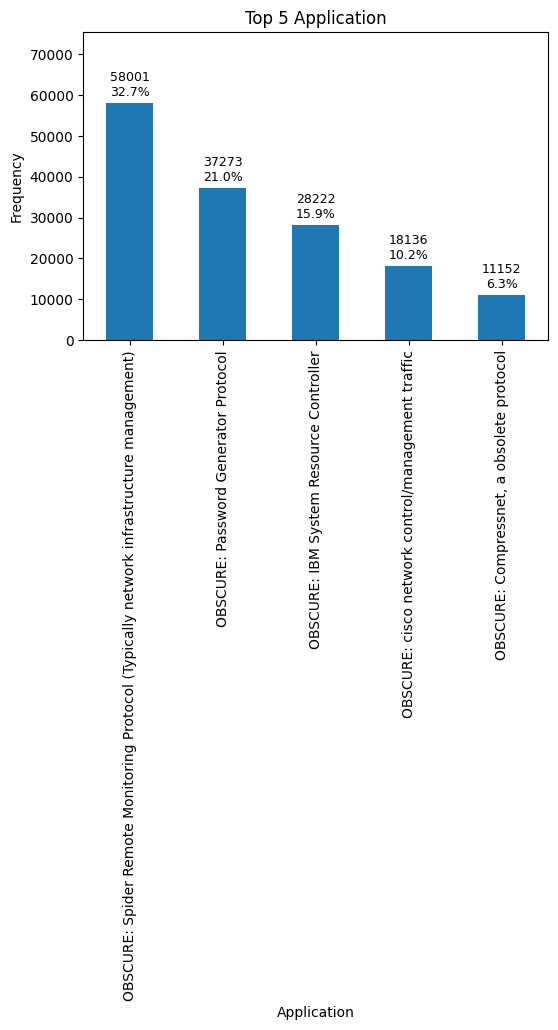

In [14]:
application_df = df_data_2.apply(infer_application, axis=1).reset_index()
application_df.columns = ["index", "Application"]
# if i try rotating here the alignment goes haywire
draw_1_var_bar_chart("Application", df=application_df, top_n=5, rot = 90)

<Axes: title={'center': 'Top 5 dst Port'}, xlabel='dst Port', ylabel='Frequency'>

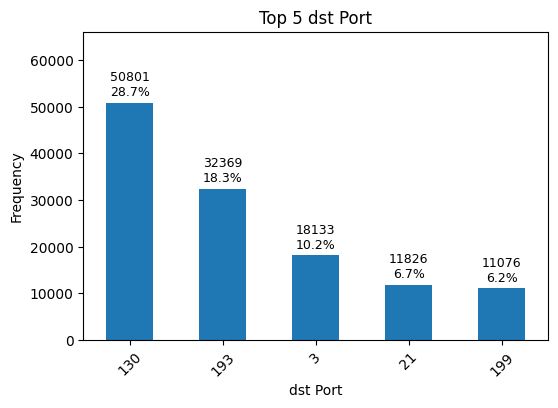

In [15]:
draw_1_var_bar_chart("dst Port", df_data_2)

In [16]:
# Investigating the forbidden 1073741823 port
forbidden_port_df = df_data_2[
    (df_data_2["dst Port"] == 1073741823) |
    (df_data_2["dst Port"] == "1073741823") |
    (df_data_2["src Port"] == 1073741823) |
    (df_data_2["src Port"] == "1073741823")
]
display(forbidden_port_df)

# honestly cant find any pattern other than adst mac often cc4e249c6300. 
# cc4e249c6300 works on IBM System Resource Controller or cisco network control/management traffic
# though src_ip = "-" and dst_ip = "-" looks funny

,Flow,Agent IP,src Port,dst Port,src_MAC,dst_MAC,ethernet_type,dst vlan,src vlan,src_ip,dst_ip,tcp6 udp17,ip_type_of_service,ip_time_to_live,src port transport level,dst port transport level,tcp flags,packet size,ip size,sampling rate
8657,FLOW,203.30.38.251,199,1073741823,544b8cf9a7df,cc4e249c6300,0x0800,600,600,221.204.226.22,202.179.249.58,1,0x00,43,8,0,0x00,106,84,2048
34085,FLOW,203.30.38.251,199,1073741823,544b8cf9a7df,cc4e249c6300,0x0800,600,600,202.179.248.2,203.30.38.252,6,0xc0,63,54659,639,0x18,130,108,2048
41777,FLOW,203.30.38.251,199,1073741823,544b8cf9a7df,cc4e249c6300,0x0800,600,600,202.179.248.2,203.30.38.252,6,0xc0,63,54659,639,0x18,151,129,2048
81444,FLOW,203.30.38.251,199,1073741823,544b8cf9a7df,cc4e249c6300,0x0800,600,600,112.29.150.31,202.179.249.58,1,0x04,43,8,0,0x10,106,84,2048
82214,FLOW,203.30.38.251,199,1073741823,544b8cf9a7df,cc4e249c6300,0x0800,600,600,202.179.248.2,203.30.38.252,6,0xc0,63,54659,639,0x18,82,60,2048
85753,FLOW,203.30.38.251,21,1073741823,6c9ced25f6bb,ffffffffffff,0x0806,2121,2121,123.136.64.7,74.125.68.108,6,0x00,59,31035,993,0x18,64,46,2048
87376,FLOW,203.30.38.251,129,1073741823,64f69dd64b9e,01000ccccccd,0x0000,1800,1800,-,-,0,0x00,0,0,0,0x00,72,64,2048
104371,FLOW,203.30.38.251,199,1073741823,544b8cf9a7df,cc4e249c6300,0x0800,600,600,202.179.248.2,203.30.38.252,6,0xc0,63,54659,639,0x18,466,444,2048
107386,FLOW,203.30.38.251,21,1073741823,001c739c3a1a,cc4e249c6314,0x0806,2121,2121,117.121.249.253,123.136.64.7,6,0x00,58,80,55192,0x10,64,46,2048
119107,FLOW,203.30.38.251,21,1073741823,cc4e249b8a00,ffffffffffff,0x0806,2121,2121,103.10.124.69,202.21.158.12,6,0x00,126,80,23177,0x10,64,46,2048


,ip,city,region,country,loc,org,postal,timezone,readme
0,203.30.38.251,Singapore,Singapore,SG,"1.2897,103.8501",AS23855 Singapore Advanced Research and Educat...,018989,Asia/Singapore,https://ipinfo.io/missingauth


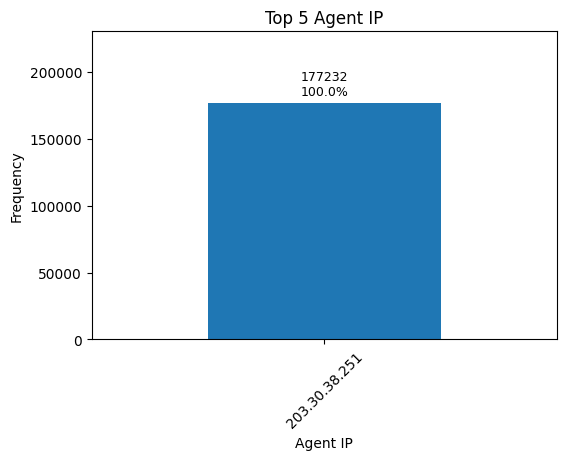

In [17]:
# well thats underwhelming ig Agent IP is SINGAREN so this data is Collected within SINGAREN
draw_1_var_bar_chart("Agent IP",df_data_2)
display_ip_details("203.30.38.251")

In [18]:
# Investigating funny src_ip = "-" and dst_ip = "-"

no_ip_df = df_data_2[
    (df_data_2["src_ip"] == "-") &
    (df_data_2["dst_ip"] == "-")
]
display(no_ip_df)
# well i guess its just that one singular transmission??

,Flow,Agent IP,src Port,dst Port,src_MAC,dst_MAC,ethernet_type,dst vlan,src vlan,src_ip,dst_ip,tcp6 udp17,ip_type_of_service,ip_time_to_live,src port transport level,dst port transport level,tcp flags,packet size,ip size,sampling rate
87376,FLOW,203.30.38.251,129,1073741823,64f69dd64b9e,01000ccccccd,0x0000,1800,1800,-,-,0,0x00,0,0,0,0x00,72,64,2048


To the src_ip = "-" and dst_ip = "-" mystery:

GPT says:

Header truncation (most common)
sFlow samples only the first N bytes of the packet. If N is too small and the capture truncated before the IPv4/IPv6 header (for example because of VLAN/MPLS tags or large L2 header), the collector will show L2 fields (MACs) but no IPs.

Non-IP / L2-only traffic
The sampled packet could be a purely Layer-2 frame (e.g., certain control frames, some tunneled L2 traffic) so there is no IP header to parse.

Encapsulation / tunneling (VXLAN, GRE, IP-in-IP, MPLS)
The visible header may be an outer header the collector doesn’t parse to reach the inner IP header. If the inner packet carried the IPs, but the exporter didn’t decapsulate (or the sample truncated before the inner header), the collector will show no IPs.

Malformed or corrupted sample
The sampled bytes might be corrupted or mis-aligned so the parser fails to locate IP header fields.

Exporter/parser bug or mismatched format
The device exporting sFlow may send fields in a way your collector/parser doesn’t expect (different sFlow version, vendor-specific layout), so the collector can extract MACs but not IPs.

Privacy/anonymization or deliberate redaction
Some exporters can be configured to omit IP addresses for privacy — you’d still see agent and L2 fields.

NAT / offload / hardware acceleration
In some hardware offload scenarios the flow recorder sees frames with non-standard fields (or only flow metadata) and not full IP headers.

Value parsing weirdness
Odd field values (e.g. ethernet_type = 0x0000 or dst port = 1073741823) suggest parsing/mapping problems — the collector may be misinterpreting bytes as ports/ethertype.

### Total Traffic

In [19]:
# Hey TA if this is taking too much space i think its fine to just change all the df traffic, df udp tcp to work on df_data_2 directly
# i personally like to keep df data 2 completely unchanged so easy to remember what df data 2 has
df_traffic = df_data_2.copy()
df_traffic["ip size"] = pd.to_numeric(df_traffic["ip size"], errors="raise")
df_traffic["sampling rate"] = pd.to_numeric(df_traffic["sampling rate"], errors="raise")
df_traffic["estimated_bytes"] = df_traffic["ip size"] * df_traffic["sampling rate"]

total_bytes = df_traffic["estimated_bytes"].sum()

print(f"Estimated total traffic (bytes): {total_bytes}")
print(f"In MB: {total_bytes / (1024**2):.2f} MiB")
print(f"In GB: {total_bytes / (1024**3):.2f} GiB")

Estimated total traffic (bytes): 348026368000
In MB: 331903.81 MiB
In GB: 324.12 GiB


### Proportion of TCP and UDP packets

In [ ]:
df_tcp_udp = df_data_2.copy()

tcp_count = (df_tcp_udp["tcp6 udp17"] == "6").sum()
udp_count = (df_tcp_udp["tcp6 udp17"] == "17").sum()
total = df_tcp_udp.shape[0]

tcp_prop = tcp_count / total 
udp_prop = udp_count / total

print(f"TCP packets: {tcp_count} ({tcp_prop:.2%})")
print(f"UDP packets: {udp_count} ({udp_prop:.2%})")
print(f"No. of other packets: {df_data_2.shape[0] - total}")


TCP packets: 137707 (77.70%)
UDP packets: 36852 (20.79%)
No. of other packets: 0


### Top 5 communications pair

In [36]:
# top5_pairs_idx = df_data_2[["src_ip", "dst_ip"]].value_counts().head(5).index
# top5_pairs_df = df_data_2[
#     df_data_2.set_index(['src_ip', 'dst_ip']).index.isin(top5_pairs_idx)
# ]
# display(top5_pairs_df)

top5_pairs = df_data_2[["src_ip", "dst_ip"]].value_counts().head(5).reset_index()

display(top5_pairs)

nd_top5_pairs = np.array(top5_pairs)
for idx, (src_ip, dst_ip, count) in enumerate(nd_top5_pairs):
    print(("--------------"))
    print(f"No. {idx + 1}: \nCount: {count}\nPercentage of total no. packets: {count/df_data_2.shape[0]:.2%}")
    print(f"Source: {src_ip}")
    display_ip_details(src_ip)
    print(f"Destination: {dst_ip}")
    display_ip_details(dst_ip)


,src_ip,dst_ip,count
0,130.14.250.7,103.37.198.100,3739
1,171.67.77.19,192.122.131.36,2656
2,129.99.230.54,137.132.22.74,2097
3,137.132.228.42,137.131.17.212,1553
4,155.69.252.133,138.75.242.36,1475


--------------
No. 1: 
Count: 3739
Percentage of total no. packets: 2.11%
Source: 130.14.250.7


,ip,hostname,city,region,country,loc,org,postal,timezone,readme
0,130.14.250.7,ftp22-1.be-md.ncbi.nlm.nih.gov,Baltimore,Maryland,US,"39.2904,-76.6122",AS70 National Library of Medicine,21203,America/New_York,https://ipinfo.io/missingauth


Destination: 103.37.198.100


,ip,city,region,country,loc,org,postal,timezone,readme
0,103.37.198.100,Singapore,Singapore,SG,"1.2994,103.7876",AS23767 A-STAR,138632,Asia/Singapore,https://ipinfo.io/missingauth


...

,ip,city,region,country,loc,org,postal,timezone,readme
0,137.131.17.212,Phoenix,Arizona,US,"33.4665,-111.9984",AS31898 Oracle Corporation,85008,America/Phoenix,https://ipinfo.io/missingauth


--------------
No. 5: 
Count: 1475
Percentage of total no. packets: 0.83%
Source: 155.69.252.133


,ip,hostname,city,region,country,loc,org,postal,timezone,readme
0,155.69.252.133,ntume23.ntu.edu.sg,Singapore,Singapore,SG,"1.2897,103.8501",AS9419 Nanyang Technological University,018989,Asia/Singapore,https://ipinfo.io/missingauth


Destination: 138.75.242.36


,ip,hostname,city,region,country,loc,org,postal,timezone,readme
0,138.75.242.36,36.242.75.138.unknown.m1.com.sg,Punggol,Singapore,SG,"1.4144,103.9069",AS4773 MobileOne Ltd. Mobile/Internet Service ...,820310,Asia/Singapore,https://ipinfo.io/missingauth


### Visualising the communication between different IP Hosts

1. NxN matrix of src vs dst IPs.
2. 
networkx + matplotlib

pyvis (interactive HTML)

Gephi (export CSV and view externally)
3. Traffic Matrix (Pivot Table or Heatmap)
4. Sankey Diagram (Flow Volume)
5. Geolocation Plot (If IPs are routable)